# Import Libraries

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import warnings
warnings.filterwarnings('ignore')

In [4]:
import random
import numpy as np
seed = 42

tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

## Dataset Collection

In [5]:
dataset_path = r"C:\Users\Praveen\Downloads\PRCP-1001-RiceLeaf\Data"

**Insight:**

The dataset consists of three disease classes, making it a multi-class classification problem. However, the limited number of images (~120) increases the risk of overfitting and limits the model’s ability to generalize.

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1/255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
    
)

val_datagen = ImageDataGenerator(
    rescale=1/255,
    validation_split=0.2
)

## Data Preprocessing (Data Loading)

In [7]:
train_data = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(128, 128),
    batch_size=8,
    class_mode='categorical',
    subset='training',
    seed = 42
)

val_data = val_datagen.flow_from_directory(
    dataset_path,
    target_size=(128, 128),
    batch_size=8,
    class_mode='categorical',
    subset='validation',
    seed = 42
)

Found 96 images belonging to 3 classes.
Found 23 images belonging to 3 classes.


**Insight:**

Resizing images ensures uniform input size, while normalization stabilizes training. Data augmentation helps simulate real-world variations and reduces overfitting.Using directory-based loading simplifies data management and allows automatic labeling. Splitting into training and validation ensures unbiased model evaluation.

## Model Building (CNN)

In [8]:
model = Sequential([

    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(2,2),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.5), 

    Dense(3, activation='softmax')   # 3 classes
])

**Insight:**

CNN layers effectively extract spatial features such as edges, textures, and disease patterns from leaf images, making them suitable for image classification tasks.

## Model Compilation

In [9]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

**Insight:**

The Adam optimizer enables efficient gradient updates, while categorical crossentropy is suitable for multi-class classification problems.

## Model Training

In [32]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
       callbacks=[early_stop]

)

Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 370ms/step - accuracy: 0.7812 - loss: 0.5014 - val_accuracy: 0.6087 - val_loss: 1.1752
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 340ms/step - accuracy: 0.7812 - loss: 0.4208 - val_accuracy: 0.5652 - val_loss: 1.4549
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 341ms/step - accuracy: 0.7500 - loss: 0.4999 - val_accuracy: 0.7391 - val_loss: 0.7360
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 336ms/step - accuracy: 0.7917 - loss: 0.4559 - val_accuracy: 0.7826 - val_loss: 0.8231
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 337ms/step - accuracy: 0.7604 - loss: 0.4572 - val_accuracy: 0.5652 - val_loss: 0.9390
Epoch 6/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 341ms/step - accuracy: 0.8021 - loss: 0.4188 - val_accuracy: 0.6087 - val_loss: 1.2075


**Insight:**

The model gradually improves accuracy over epochs, learning important features of each disease class. Early stopping helps prevent unnecessary training.

## Model Evaluation

In [37]:
loos,acc =model.evaluate(val_data)
print('validation data:',acc)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 202ms/step - accuracy: 0.7391 - loss: 0.7360
validation data: 0.739130437374115


**Insight:**

Validation accuracy indicates how well the model generalizes to unseen data. Slight fluctuations may occur due to the small dataset size.

# Visualization (Predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


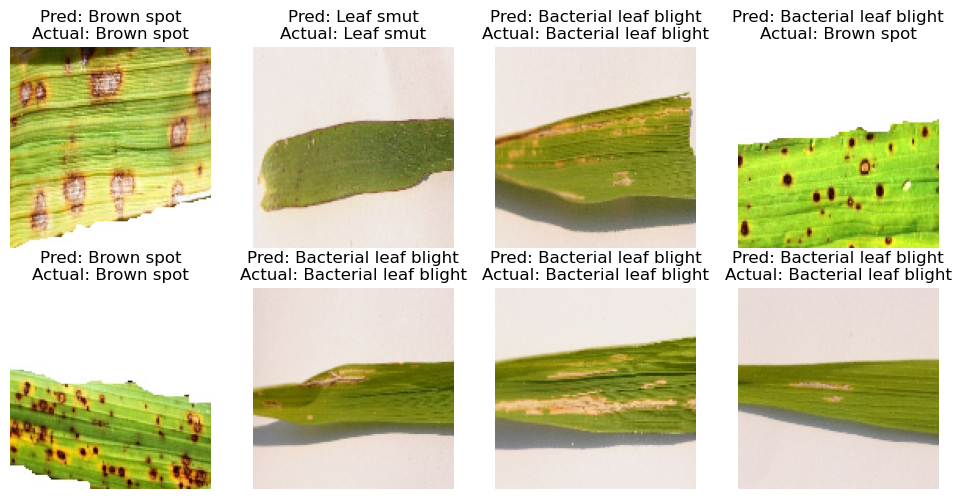

In [35]:
import numpy as np

class_names = list(train_data.class_indices.keys())

x, y = next(val_data)

predictions = model.predict(x)

plt.figure(figsize=(12,12))

for i in range(len(x)):
    plt.subplot(4,4,i+1)
    plt.imshow(x[i])
    plt.axis('off')
    
    pred_label = class_names[np.argmax(predictions[i])]
    true_label = class_names[np.argmax(y[i])]
    
    plt.title(f"Pred: {pred_label}\nActual: {true_label}")
    plt.axis('off')

plt.show()

**Insight:**

The trained model can successfully classify new rice leaf images, demonstrating its practical application in disease detection.

# Problems Faced

**1. Small Dataset Size :** - The dataset contained only 120 images, which is very limited for training a deep learning model.

**2. Overfitting Issue :** - The model achieved high training accuracy but lower validation accuracy.

**3. Data Imbalance & Variability :** - Although classes were equal in number, images had variations in lighting, background, and quality.

**4. Model Instability :** - Accuracy fluctuated during training (different results on each run).

**5. Hyperparameter Tuning Difficulty :** - Incorrect settings reduced model performance,
                                           Required multiple trials to optimize

# Final Faced

**“The project highlighted the importance of balancing model complexity and dataset size. Simpler models performed better on small datasets, and regularization techniques significantly improved validation accuracy.”**


**“Due to the limited dataset size, the model showed slight variability in validation accuracy. Techniques such as data augmentation, dropout, and early stopping were applied to improve generalization and reduce overfitting.”**